# Homework 5: Statistical Hypothesis Testing (Chi-Square & ANOVA)


## Dataset Setup Instructions

To complete this assignment, download **IBM HR Analytics Employee Attrition & Performance Dataset** from github or kaggle.


### Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)
1. Formulate a research question examining whether two workforce attributes are associated (e.g., *Is an employee's Department associated with their likelihood of working OverTime? Is Gender associated with different Job Roles?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Compute a contingency table showing the exact cross-tabulated counts of employees across these categories.
4. Execute a Chi-Square Test of Independence at a 5% significance level ($\alpha = 0.05$). Report the test statistic, degrees of freedom, and the p-value.
5. Create a grouped or stacked bar chart to visually compare the proportional distribution between the groups.
6. Write 2–3 sentences interpreting what these findings mean for an HR manager trying to address workplace imbalances.

---

### Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)
1. Formulate a research question evaluating whether average compensation scales vary across different structural groups (e.g., *Does the mean MonthlyIncome differ significantly across the 3 distinct Departments? Does it differ based on MaritalStatus?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Run a One-Way ANOVA test at a 5% significance level ($\alpha = 0.05$). Report the F-statistic and the p-value.
4. Generate a boxplot or violin plot displaying `MonthlyIncome` across the different categorical groups.
5. Write 2–3 sentences interpreting your statistical conclusions. If the test is significant, note which specific groups appear to stand out.

---

## Part 3: Assessing Decision Errors in HR Policy
Select **either** your Chi-Square test or your ANOVA test from Part 1 or 2. For that specific test, write a brief analysis detailing:
1. Exactly what a Type I error (false positive) translates to in the context of your specific workplace hypothesis.
2. Exactly what a Type II error (false negative) translates to in the context of your specific workplace hypothesis.
3. From a corporate governance, budget planning, or employee retention standpoint, explain which of these two errors carries a worse operational risk for the company, and why.



In [11]:
import numpy as np
import pandas as pd

import scipy.stats as stats
import pingouin as pg

import matplotlib.pyplot as plt
import seaborn as sns


In [12]:
dataFrame = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
dataFrame.info()
print()
dataFrame.head()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# Part 1:

### Question: Does the field of education a person specializes in affect their chances at getting higher level jobs?

#### Null Hypothesis:
There is no correlation between the field of education someone specializes in and the level of their job <br>
#### Alternate Hypothesis:
The field of education someone specializes in has an affect on what level of job they tend to acquire *(choosing a certain area of study could potentially improve/reduce your chances at getting a higher/lower level job)*

In [13]:

## Contingency table for 'EducationField' and 'JobLevel'

contTable = pd.crosstab(dataFrame['EducationField'], dataFrame['JobLevel'])
contTableDisplay = pd.crosstab(dataFrame['EducationField'], dataFrame['JobLevel'], margins=True)

print(f"####### Contingency Table for [Education Field] and [Job Level]: #######\n\n{contTableDisplay}\n")


####### Contingency Table for [Education Field] and [Job Level]: #######

JobLevel            1    2    3    4   5   All
EducationField                                
Human Resources    13    7    1    2   4    27
Life Sciences     229  216   87   48  26   606
Marketing          21   87   32   11   8   159
Medical           188  153   63   36  24   464
Other              30   34   11    3   4    82
Technical Degree   62   37   24    6   3   132
All               543  534  218  106  69  1470



In [14]:

## Chi Square Test of Independence

alphaVal = 0.05
chi_Stat, pValue, dof, expectVals = stats.chi2_contingency(contTable)

## compare p-value of test to alpha (5% significance level)
## to reject/fail-to-reject Null Hypothesis

print(f"Chi Square statistic: {chi_Stat:5f}")
print(f"p-value: {pValue:5f}")
print(f"Degrees of freedom: {dof}")
print(f"\nExpected frequencies:\n{expectVals}\n")

if pValue < alphaVal:
    print("{ Reject H0 }: There is evidence that a person's field of education has a meaningful effect on the level of the jobs available to them\n")
else:
    print("{ Fail to reject H0 (Null Hypothesis) }: There is no significant relationship between ", end="")
    print("someone's specialized field of education and what level of job they attain\n")


Chi Square statistic: 69.050404
p-value: 0.000000
Degrees of freedom: 20

Expected frequencies:
[[  9.97346939   9.80816327   4.00408163   1.94693878   1.26734694]
 [223.84897959 220.13877551  89.86938776  43.69795918  28.44489796]
 [ 58.73265306  57.75918367  23.57959184  11.46530612   7.46326531]
 [171.39591837 168.55510204  68.81088435  33.4585034   21.77959184]
 [ 30.28979592  29.7877551   12.16054422   5.91292517   3.84897959]
 [ 48.75918367  47.95102041  19.5755102    9.51836735   6.19591837]]

{ Reject H0 }: There is evidence that a person's field of education has a meaningful effect on the level of the jobs available to them



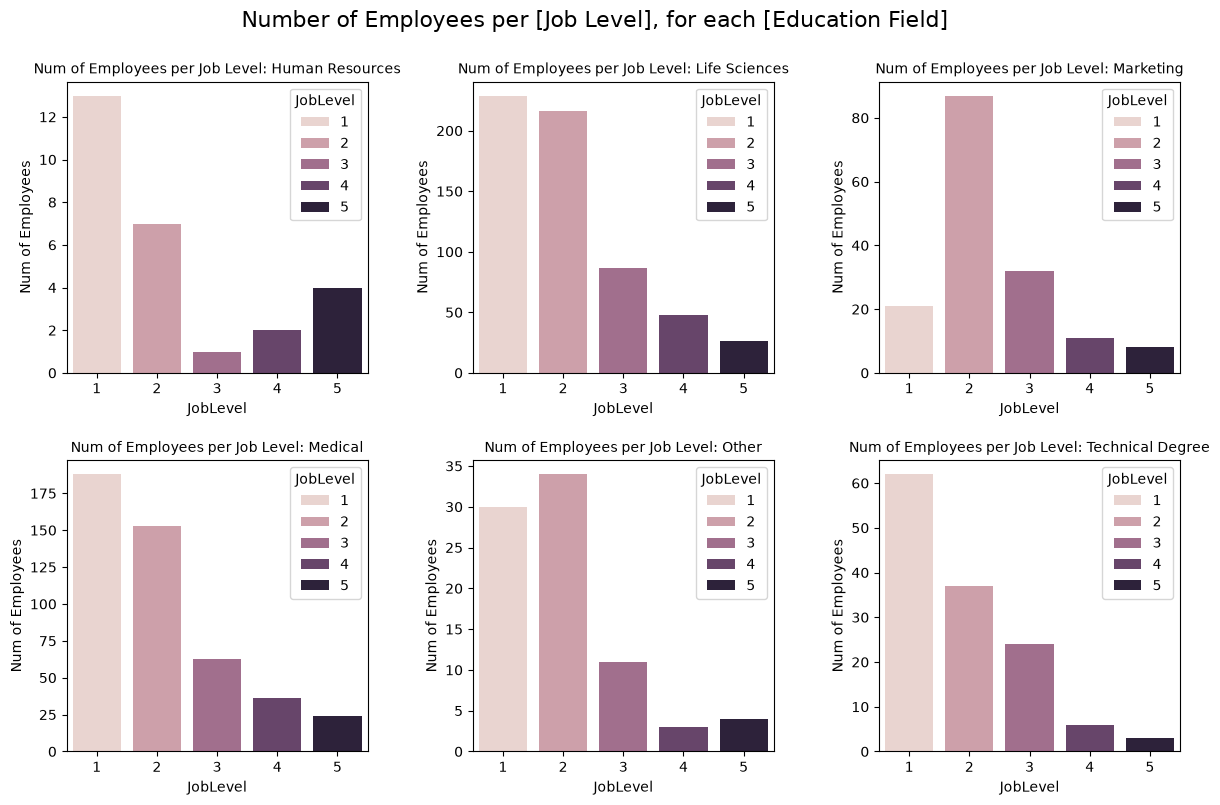

In [15]:

field_HR = pd.DataFrame(contTable.iloc[0])
field_HR.reset_index(inplace=True)

field_LifeSci = pd.DataFrame(contTable.iloc[1])
field_LifeSci.reset_index(inplace=True)

field_Market = pd.DataFrame(contTable.iloc[2])
field_Market.reset_index(inplace=True)

field_Med = pd.DataFrame(contTable.iloc[3])
field_Med.reset_index(inplace=True)

field_Other = pd.DataFrame(contTable.iloc[4])
field_Other.reset_index(inplace=True)

field_TechDegr = pd.DataFrame(contTable.iloc[5])
field_TechDegr.reset_index(inplace=True)


figur, axi = plt.subplots(2, 3, figsize=(12, 8))
figur.suptitle("Number of Employees per [Job Level], for each [Education Field]", y=1.0, fontsize=16)

hmrs = sns.barplot(data=field_HR, x='JobLevel', y='Human Resources', hue='JobLevel', ax=axi[0,0])
axi[0,0].set_title("Num of Employees per Job Level: Human Resources", fontsize=10)
axi[0,0].set_ylabel("Num of Employees")

lfsc = sns.barplot(data=field_LifeSci, x='JobLevel', y='Life Sciences', hue='JobLevel', ax=axi[0,1])
axi[0,1].set_title("Num of Employees per Job Level: Life Sciences", fontsize=10)
axi[0,1].set_ylabel("Num of Employees")

mrkt = sns.barplot(data=field_Market, x='JobLevel', y='Marketing', hue='JobLevel', ax=axi[0,2])
axi[0,2].set_title("Num of Employees per Job Level: Marketing", fontsize=10)
axi[0,2].set_ylabel("Num of Employees")

medc = sns.barplot(data=field_Med, x='JobLevel', y='Medical', hue='JobLevel', ax=axi[1,0])
axi[1,0].set_title("Num of Employees per Job Level: Medical", fontsize=10)
axi[1,0].set_ylabel("Num of Employees")

othr = sns.barplot(data=field_Other, x='JobLevel', y='Other', hue='JobLevel', ax=axi[1,1])
axi[1,1].set_title("Num of Employees per Job Level: Other", fontsize=10)
axi[1,1].set_ylabel("Num of Employees")

tcdg = sns.barplot(data=field_TechDegr, x='JobLevel', y='Technical Degree', hue='JobLevel', ax=axi[1,2])
axi[1,2].set_title("Num of Employees per Job Level: Technical Degree", fontsize=10)
axi[1,2].set_ylabel("Num of Employees")

plt.tight_layout()
plt.subplots_adjust(wspace=0.35,hspace=0.3)
plt.show()



### Analysis:
Through the process of the Chi Square Test, when comparing the expected frequency values to what was actually observed in the data, the most noticeable/substantial differences between the two appear in the lower job levels, particularly among those who specialized in Marketing, Medical, and Technical Degrees with their education.

According to the expected frequencies, if educational field *didn't* have a significant effect on job level, then it's estimated that out of all people who studied in Marketing, roughly ~37% of them would acquire a level 1 job, ~36% of them would get a level 2, and ~15% would reach level 3 *(expected freqs. of Marketing: ~59, ~58, and ~24; divided by total people in Marketing {159} to get percentage out of total)*.

Instead, what was observed in the actual data was that only about ~13% and ~20% of employees who had studied Marketing were in a level 1 and 3 job respectively, while **~54%** of them were in a level 2. <br> A similar trend can be seen among those who studied in Medical and Technical Degrees *(although with a less substantial difference)*, with the proportions in the observed data shifting to have more people in level 1 jobs, and less in level 2, compared to the estimated frequencies.

This shows that there may be some kind of influence, bias, incentive, or otherwise behind how people with certain education backgrounds *(Marketing in particular, followed by Technical Degrees and Medical)* are selected in the workplace, especially in comparison to the proportions of other educational fields, which tend to better align with the estimations.

# Part 2:

### Question: Is there a relationship between the amount of traveling someone does for their job, and their income?

#### Null Hypothesis:
There is no correlation between a person's frequency of business travel and their monthly income <br>
#### Alternate Hypothesis:
How frequently a person travels for business reasons has an affect on their monthly income rate *(traveling more/less for their job can lead to an employee earning greater/lesser average pay)*

In [16]:

dataRenameCopy = dataFrame.rename(columns={'BusinessTravel':'Travel'})

print(dataRenameCopy['Travel'].unique())
print()

## possible values for ['BusinessTravel']:
## "Travel_Rarely", "Travel_Frequently", "Non-Travel"

travelStats = dataRenameCopy.groupby('Travel')['MonthlyIncome'].agg(['mean', 'std', 'min', 'max'])
print(f"#### Stats on [MonthlyIncome] per [BusinessTravel] frequency category ####:\n{travelStats}\n")


<ArrowStringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str

#### Stats on [MonthlyIncome] per [BusinessTravel] frequency category ####:
                          mean          std   min    max
Travel                                                  
Non-Travel         6261.946667  4493.415018  1051  19973
Travel_Frequently  6193.725632  4371.990442  1091  19847
Travel_Rarely      6619.707574  4821.853698  1009  19999



In [18]:

## One-Way ANOVA

travel2Income = dataRenameCopy.anova(dv='MonthlyIncome', between='Travel', detailed=True)
print(f"############ ANOVA table: ############\n{travel2Income}")

## compare p-value of test to alpha (5% significance level)
## to reject/fail-to-reject Null Hypothesis

alphaVal = 0.05
f_Stat = travel2Income['F'][0]
pVal_2 = travel2Income['p_unc'][0]

print(f"\nF-statistic: {f_Stat:.5f}")
print(f"p-value: {pVal_2:.5f}\n")

if pVal_2 < alphaVal:
    print("{ Reject H0 }: There is evidence that how frequently an employee travels for business has a ", end="")
    print("meaningful effect on their monthly income\n")
else:
    print("{ Fail to reject H0 (Null Hypothesis) }: There is no significant relationship between ", end="")
    print("how much business travel an employee does and \ntheir monthly income\n")


############ ANOVA table: ############
   Source            SS    DF            MS         F    p_unc       np2
0  Travel  4.941757e+07     2  2.470879e+07  1.114948  0.32821  0.001518
1  Within  3.251076e+10  1467  2.216139e+07       NaN      NaN       NaN

F-statistic: 1.11495
p-value: 0.32821

{ Fail to reject H0 (Null Hypothesis) }: There is no significant relationship between how much business travel an employee does and 
their monthly income



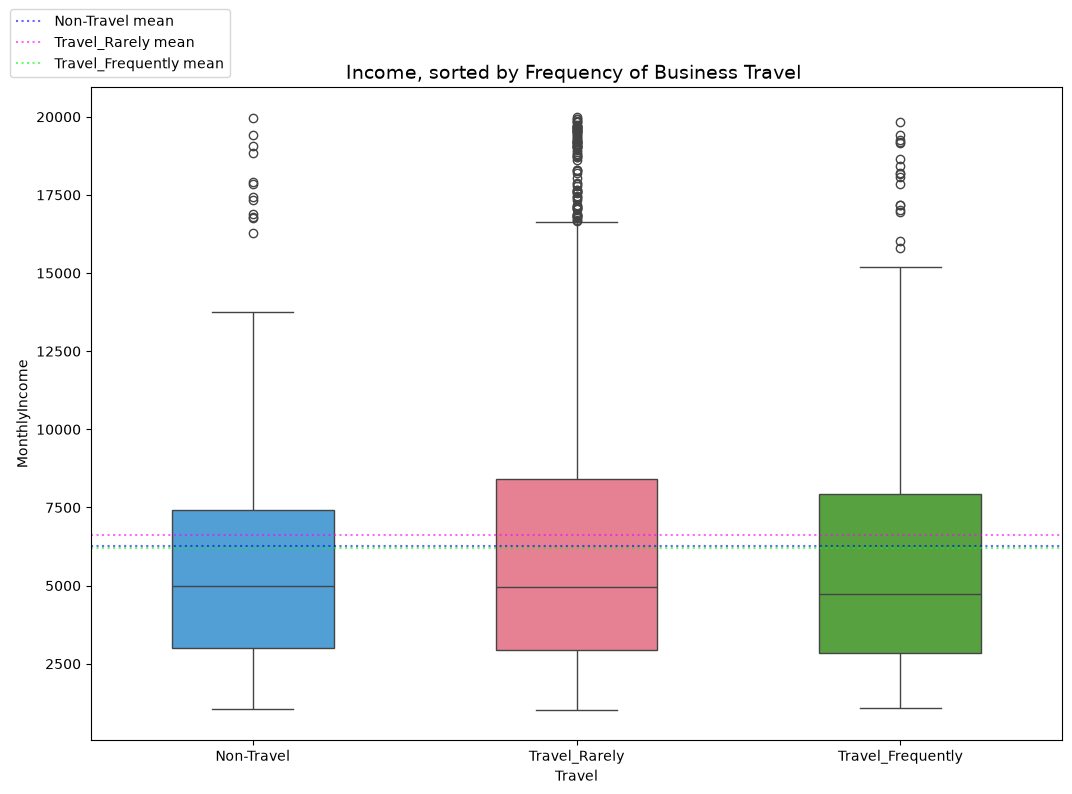

In [9]:
noTravelMean = travelStats.loc['Non-Travel', 'mean']
lowTravelMean = travelStats.loc['Travel_Rarely', 'mean']
highTravelMean = travelStats.loc['Travel_Frequently', 'mean']


plt.figure(figsize=(11,8))

sns.boxplot(
    data=dataRenameCopy,
    x='Travel',
    y='MonthlyIncome',
    hue='Travel',
    order=['Non-Travel', 'Travel_Rarely', 'Travel_Frequently'],
    palette='husl',
    width=0.5,
)

plt.axhline(noTravelMean, color='blue', linestyle=':', alpha=0.6, label="Non-Travel mean")
plt.axhline(lowTravelMean, color='magenta', linestyle=':', alpha=0.6, label="Travel_Rarely mean")
plt.axhline(highTravelMean, color='lime', linestyle=':', alpha=0.6, label="Travel_Frequently mean")

plt.legend(loc='upper right', bbox_to_anchor=(0.15, 1.13))
plt.title("Income, sorted by Frequency of Business Travel ", fontsize=14)
plt.tight_layout()
plt.show()


### Analysis:
Through the process of the One-Way ANOVA, when comparing the calculated p-value of the data to alpha *{corresponding with a 5% significance level}*, there isn't enough evidence to prove that the amount of travel for business reasons an employee does has a significant effect on the amount of their monthly income.

Even when looking at some of the data's simpler statistics (e.g. mean, standard deviation, min/max, etc.) it can be directly observed that between the different levels of business travel frequency, where the values of monthly income tend to fall are very similar between all of the categories. When interpreting the data through the graph, it can be seen that, although the upper ranges of values between each of the travel categories have some lighter discrepancies between them, the data is still distributed overall very similarly as well. This is supported by the F-statistic calculated by the ANOVA, as its value is very close to 1, showing that the variance of data between each group of employees is about the same as the variation among employees within each group (nearly a ratio of 1:1 for variance between/within groups). Since the monthly income rate of the employees have extremely similar trends, regardless of which category they have been placed into, the analysis strongly suggests that the amount of traveling someone does for work doesn't really affect their income rate. <br><br>


Based on the more indistinct details that can be analyzed from the data (from the graph especially, which visualizes overall trends more clearly), there are many potential explanations for the smaller differences between the groups of travel frequency, that could come from factors other than the core test variable being analyzed. <br>
A large majority of the data seems to be heavily clustered towards the lower ranges of values, and as the value of an employee's monthly income increases, there is less and less of the data distributed within those ranges as you go higher. The few noteworthy outliers of the data tend to drift around the very top range of possible values.

A way this information from the graph could be interpreted is that:
- It is typical for a company to have various job positions of differing grades, with each those grades naturally having their own minimum requirements for hire, and compensation based on their value/importance to the company; it wouldn't be practical for all employees to be paid the exact same wages *(the company's budget wouldn't be able to handle it either)*, nor would it make sense for all position levels to be equally accessible, in spite of the effort required to attain and/or maintain the position. 
- Therefore, it makes sense for job positions that are of higher degree to be less common due to being less accessible due to stricter requirements to obtain the position, and would make up a much smaller portion of a company's total employees; in return, these high-degree jobs pay much higher wages than most others.
- In contrast, lower tier jobs with lesser pay can often have more available opportunities *(simpler or less critical tasks can more safely be delegated to any average person that may not have certain specialized capabilities/experience)*, and generally make up a larger portion of a company's employees in comparison to jobs with greater pay.

In summary, this would be an explaination of the large quantity of data being condensed towards the bottom, representing the majority of average of employees (with average income) within the company. The higher employees with higher monthly income would be fewer and farther between, correlating to the outlier values in the data located towards the top of the graph. Accordingly, this reasoning can also serve to prove how other factors can cause variance in the date between the different groups within the hypothesis test, besides the effect of the independent variable being analyzed.


# Part 3:
In the direct context for the workplace hypotheses created with these tests, and specifically in regards to testing the relationship between a person's choice in the field of study for their education and the likelihood of them attaining a certain job level *(as done in the Chi Square Test)*:
- A [ Type 1 ] Error would translate to making the claim that a person's educational field of study can affect what level of jobs they may be more or less likely be able to acquire, even when it doesn't actually have a substantial influence. If the company this analysis is being done chose to respond to the (error-prone) hypothesis test accordingly, they could plan to make arrangements to resolve any potential negative/unfair tendencies or inconsistencies in their operations; this could lead to them making some attempt to rebalance the proportions of their employees, despite it being irrelevant, or even undermining the company's success.
- A [ Type 2 ] Error would translate to making the claim that the field of education someone studied in isn't related to the level of job they end up with, but in reality there is some kind of affect that field of study has on the level of a position a person ends up with. Proceeding in-line with the error of not rejecting a false H0 could lead to the company ignoring possible issues *(regarding position assignment in particular)* that may affect their performance in the future.

Upon considering the well-being of a company and it's administration, when conducting a hypothesis test for the previously mentioned relationship between variables, a **[ Type I ]** Error would be the worse error to make for the company. If the null hypothesis that someone's educational field hasn't had an affect on how people are being designated their jobs was true, the company most likely wouldn't need to make considerable, or any, changes to how they hire and appoint their employees. Acting on an incorrect rejection of H0, and making large revisions to their current processes and structures in order to account for a bias that isn't actually there, could potentially clutter many aspects of their organization that were alright as they were, and could lead to creating new biases or interferences that weren't present before.

In addition to imposing unnecessary disorder within the overall management of the company, a Type I Error in testing the relationship between education and the designation of job grades could affect the company's budgeting in particular, in a very detrimental way. If the null hypothesis is rejected despite being true, and the company adjusted the proportions of how their employees are distributed across different levels of positions, the company would consequentially have to adjust their budget respectively as well. Employees of different job grades need to be compensated with a salary appropriate for that grade, and different divisions within the company that carry more employees of a certain level can all require different amounts of budget investment for their work functions. Disrupting the current systems in place for allocating the company's funds, even at a possible loss, in order to resolve a false issue, clearly carries massive risks.
